In [2]:
import numpy as np
import pandas as pd


def fetch_fred_series(
    series_id: str, start_date: str = "2005-01-01", is_monthly: bool = False
) -> pd.Series:
    """FRED üzerinden seri çeker; günlük/haftalık serileri gerekirse aylık ortalamaya çevirir."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url)

    date_col = df.columns[0]
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.set_index(date_col)

    s = pd.to_numeric(df[series_id], errors="coerce")
    s.name = series_id
    s = s[s.index >= start_date]

    # Eğer aylık tablo için çekiliyorsa ve seri günlük/haftalıksa (ör. DTWEXBGS), aylık ortalamasını al
    if is_monthly:
        s = s.resample("ME").mean()
        s.index = s.index.to_period("M")

    return s


# 1. ÇEYREKLİK SERİLER (Reel Hedefler + Nominal Ağırlıklar)
q_tickers = {
    "GDPC1": "real_GDP",
    "PCECC96": "real_C",
    "GPDIC1": "real_I",
    "GCEC1": "real_G",
    "EXPGSC1": "real_X",
    "IMPGSC1": "real_M",
    "GDP": "nom_GDP",
    "PCEC": "nom_C",
    "GPDI": "nom_I",
    "GCE": "nom_G",
    "EXPGS": "nom_X",
    "IMPGS": "nom_M",
}

print("Çeyreklik veriler çekiliyor...")
q_raw = pd.concat(
    [fetch_fred_series(k, is_monthly=False) for k in q_tickers.keys()], axis=1
)
q_raw.rename(columns=q_tickers, inplace=True)
q_raw.index = q_raw.index.to_period("Q")

q_targets = pd.DataFrame(index=q_raw.index)
for col in ["real_GDP", "real_C", "real_I", "real_G", "real_X", "real_M"]:
    q_targets[f"g_{col}"] = np.log(q_raw[col] / q_raw[col].shift(1)) * 100

q_weights = pd.DataFrame(index=q_raw.index)
for comp in ["C", "I", "G", "X", "M"]:
    q_weights[f"w_{comp}"] = (q_raw[f"nom_{comp}"] / q_raw["nom_GDP"]).shift(1)


# 2. AYLIK SERİLER (12 Feature + 4 Fiyat Endeksi)
m_tickers = [
    "RSAFS",
    "DSPIC96",
    "PAYEMS",  # C
    "DGORDER",
    "HOUST",
    "INDPRO",  # I
    "USGOVT",
    "MTSO133FMS",  # G
    "BOPTEXP",
    "DTWEXBGS",  # X (DTWEXBGS otomatik aylık ortalamaya çevrilecek)
    "BOPTIMP",
    "TCU",  # M
    "CPIAUCSL",
    "PPIACO",
    "IQ",
    "IR",  # Deflatorlar
]

print("Aylık veriler çekiliyor...")
m_raw = pd.concat(
    [fetch_fred_series(k, is_monthly=True) for k in m_tickers], axis=1
)

# 3. ÖN İŞLEME: ENFLASYON ARINDIRMA & DURAĞANLAŞTIRMA
m_proc = pd.DataFrame(index=m_raw.index)

# --- C (Tüketim) ---
real_rsafs = (m_raw["RSAFS"] / m_raw["CPIAUCSL"]) * 100
m_proc["C_rsafs"] = np.log(real_rsafs / real_rsafs.shift(1)) * 100
m_proc["C_dspic"] = np.log(m_raw["DSPIC96"] / m_raw["DSPIC96"].shift(1)) * 100
m_proc["C_payems"] = np.log(m_raw["PAYEMS"] / m_raw["PAYEMS"].shift(1)) * 100

# --- I (Yatırım) ---
real_dgorder = (m_raw["DGORDER"] / m_raw["PPIACO"]) * 100
m_proc["I_dgorder"] = np.log(real_dgorder / real_dgorder.shift(1)) * 100
m_proc["I_houst"] = np.log(m_raw["HOUST"] / m_raw["HOUST"].shift(1)) * 100
m_proc["I_indpro"] = np.log(m_raw["INDPRO"] / m_raw["INDPRO"].shift(1)) * 100

# --- G (Kamu) ---
m_proc["G_usgovt"] = np.log(m_raw["USGOVT"] / m_raw["USGOVT"].shift(1)) * 100
real_mtso = (m_raw["MTSO133FMS"] / m_raw["PPIACO"]) * 100
m_proc["G_mtso_yoy"] = np.log(real_mtso / real_mtso.shift(12)) * 100

# --- X (İhracat) ---
real_boptexp = (m_raw["BOPTEXP"] / m_raw["IQ"]) * 100
m_proc["X_exp"] = np.log(real_boptexp / real_boptexp.shift(1)) * 100
m_proc["X_usd"] = np.log(m_raw["DTWEXBGS"] / m_raw["DTWEXBGS"].shift(1)) * 100

# --- M (İthalat) ---
real_boptimp = (m_raw["BOPTIMP"] / m_raw["IR"]) * 100
m_proc["M_imp"] = np.log(real_boptimp / real_boptimp.shift(1)) * 100
m_proc["M_tcu"] = m_raw["TCU"].diff(1)


# 4. U-MIDAS FREKANS EŞİTLEME (Aylık -> Çeyreklik Pivot: m1, m2, m3)
m_proc["quarter"] = m_proc.index.asfreq("Q")
m_proc["month_in_q"] = ((m_proc.index.month - 1) % 3) + 1

feature_cols = [c for c in m_proc.columns if c not in ["quarter", "month_in_q"]]

umidas_features = m_proc.pivot(
    index="quarter", columns="month_in_q", values=feature_cols
)
umidas_features.columns = [
    f"{col}_m{m}" for col, m in umidas_features.columns
]


# 5. ANA VERİ SETİNİ BİRLEŞTİRME (2006Q1 ve sonrası)
master_df = pd.concat([q_targets, q_weights, umidas_features], axis=1)
master_df = master_df[master_df.index >= "2006Q1"]

print(f"\nMaster Veri Seti Boyutu: {master_df.shape}")
print("İlk 3 çeyrek örneği:")
print(
    master_df[
        ["g_real_GDP", "g_real_C", "w_C", "C_rsafs_m1", "C_rsafs_m2", "C_rsafs_m3"]
    ].head(3)
)
print("\nSon 3 çeyrek (Canlı Nowcast Dönemi):")
print(
    master_df[
        ["g_real_GDP", "C_rsafs_m1", "C_rsafs_m2", "C_rsafs_m3"]
    ].tail(3)
)

Çeyreklik veriler çekiliyor...
Aylık veriler çekiliyor...

Master Veri Seti Boyutu: (84, 47)
İlk 3 çeyrek örneği:
        g_real_GDP  g_real_C       w_C  C_rsafs_m1  C_rsafs_m2  C_rsafs_m3
2006Q1    1.336414  1.084553  0.672107    2.229667   -0.808903    0.233914
2006Q2    0.258419  0.517108  0.669170   -0.008398   -0.637010    0.296741
2006Q3    0.149844  0.640115  0.670935   -0.224564   -0.054329   -0.088650

Son 3 çeyrek (Canlı Nowcast Dönemi):
        g_real_GDP  C_rsafs_m1  C_rsafs_m2  C_rsafs_m3
2026Q2    0.548980   -0.053217    0.558075    0.625929
2026Q3    0.828523   -0.481487    1.044788    0.178625
2026Q4         NaN   -0.137880         NaN         NaN


In [3]:
import warnings
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# XGBoost kuruluysa kullan, değilse sklearn GradientBoostingRegressor kullan
try:
    from xgboost import XGBRegressor

    def get_ml_model():
        return XGBRegressor(
            n_estimators=50,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.8,
            random_state=42,
            verbosity=0,
        )

    ml_name = "XGBoost"
except ImportError:
    from sklearn.ensemble import GradientBoostingRegressor

    def get_ml_model():
        return GradientBoostingRegressor(
            n_estimators=50,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.8,
            random_state=42,
        )

    ml_name = "GradientBoosting"


# 1. GERÇEK ZAMANLI EKSİK AY TAMAMLAMA (NO-LEAKAGE AR(1) IMPUTATION)
def forecast_missing_months(
    m_series: pd.Series, cutoff_period: pd.Period, steps: int
) -> list:
    """
    Sadece cutoff_period'a (dahil) kadar olan aylık veriyi kullanarak
    AR(1) modeliyle `steps` adım ileri tahmin üretir. (Sıfır veri sızıntısı).
    """
    hist = m_series[m_series.index <= cutoff_period].dropna()
    if len(hist) < 12:
        return [hist.mean()] * steps

    # AR(1): y_t = c + phi * y_{t-1}
    y = hist.values[1:]
    X = hist.values[:-1]
    phi, c = np.polyfit(X, y, 1)

    # Durağanlık güvenliği (patlamayı önlemek için |phi| < 0.95 sınırı)
    phi = np.clip(phi, -0.95, 0.95)

    preds = []
    last_val = hist.values[-1]
    for _ in range(steps):
        next_val = c + phi * last_val
        preds.append(next_val)
        last_val = next_val
    return preds


def build_realtime_feature_row(
    target_q: pd.Period, available_months: int
) -> pd.Series:
    """
    target_q çeyreği için yalnızca `available_months` (1, 2 veya 3) kadar
    aylık veri açıklandığı anki bilgi setini (U-MIDAS satırını) oluşturur.
    Eksik ayları (m2 ve/veya m3) o anki bilgi setiyle AR(1) tahmin ederek doldurur.
    """
    q_start_month = (target_q.quarter - 1) * 3 + 1
    m1_p = pd.Period(year=target_q.year, month=q_start_month, freq="M")
    m2_p = m1_p + 1
    m3_p = m1_p + 2

    cutoff_p = [m1_p, m2_p, m3_p][available_months - 1]
    row_dict = {}

    for col in feature_cols:
        s = m_proc[col]
        # Mevcut ayları gerçek veriden al, eksik ayları AR(1) ile tahmin et
        vals = []
        for m_idx, p in enumerate([m1_p, m2_p, m3_p], start=1):
            if m_idx <= available_months and p in s.index and pd.notna(s.loc[p]):
                vals.append(s.loc[p])
            else:
                # Kaç adım ileri tahmin gerekiyor?
                last_avail_p = (
                    cutoff_p if cutoff_p in s.dropna().index else s.dropna().index[-1]
                )
                step_ahead = (p.year - last_avail_p.year) * 12 + (
                    p.month - last_avail_p.month
                )
                step_ahead = max(1, step_ahead)
                f_vals = forecast_missing_months(s, last_avail_p, step_ahead)
                vals.append(f_vals[-1])

        row_dict[f"{col}_m1"] = vals[0]
        row_dict[f"{col}_m2"] = vals[1]
        row_dict[f"{col}_m3"] = vals[2]

    return pd.Series(row_dict)


# 2. ALT BİLEŞEN HARİTASI (BOTTOM-UP MİMARİSİ)
component_map = {
    "C": {
        "target": "g_real_C",
        "weight": "w_C",
        "sign": 1.0,
        "prefixes": ["C_rsafs", "C_dspic", "C_payems"],
    },
    "I": {
        "target": "g_real_I",
        "weight": "w_I",
        "sign": 1.0,
        "prefixes": ["I_dgorder", "I_houst", "I_indpro"],
    },
    "G": {
        "target": "g_real_G",
        "weight": "w_G",
        "sign": 1.0,
        "prefixes": ["G_usgovt", "G_mtso_yoy"],
    },
    "X": {
        "target": "g_real_X",
        "weight": "w_X",
        "sign": 1.0,
        "prefixes": ["X_exp", "X_usd"],
    },
    "M": {
        "target": "g_real_M",
        "weight": "w_M",
        "sign": -1.0,
        "prefixes": ["M_imp", "M_tcu"],
    },  # İthalat GSYİH'den düşülür
}

covid_quarters = [pd.Period("2020Q2", freq="Q"), pd.Period("2020Q3", freq="Q")]


def predict_single_quarter(
    target_q: pd.Period, available_months: int, mask_covid: bool = True
):
    """
    Belirli bir çeyrek ve bilgi seti (Ay 1, 2 veya 3) için hem Ridge hem ML
    Bottom-Up tahminlerini ve AR(1) Benchmark tahminini döndürür.
    """
    # Eğitim verisi: target_q'dan önceki tüm tamamlanmış çeyrekler
    train_df = master_df[master_df.index < target_q].dropna(subset=["g_real_GDP"]).copy()
    if mask_covid:
        train_df = train_df[~train_df.index.isin(covid_quarters)]

    # Tahmin edilecek çeyreğin o anki bilgi setine göre feature satırını oluştur
    test_x_row = build_realtime_feature_row(target_q, available_months)
    weights_row = master_df.loc[target_q]

    ridge_gdp_pred = 0.0
    ml_gdp_pred = 0.0
    comp_details = {}

    for comp, cfg in component_map.items():
        cols = [f"{p}_m{m}" for p in cfg["prefixes"] for m in [1, 2, 3]]
        sub_train = train_df[cols + [cfg["target"]]].dropna()

        X_tr = sub_train[cols]
        y_tr = sub_train[cfg["target"]]
        X_te = test_x_row[cols].values.reshape(1, -1)

        # Model 1: Ekonometrik Bridge (Ridge)
        ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
        ridge_pipe.fit(X_tr, y_tr)
        pred_r = float(ridge_pipe.predict(X_te)[0])

        # Model 2: Makine Öğrenmesi
        ml_model = get_ml_model()
        ml_model.fit(X_tr, y_tr)
        pred_m = float(ml_model.predict(X_te)[0])

        # Ağırlıklandırılmış Katkı Puanı: sign * w_{t-1} * g_hat_t
        w = float(weights_row[cfg["weight"]])
        sign = cfg["sign"]

        ridge_gdp_pred += sign * w * pred_r
        ml_gdp_pred += sign * w * pred_m

        comp_details[comp] = {
            "weight": w,
            "ridge_growth": pred_r,
            "ridge_contrib": sign * w * pred_r,
            "ml_growth": pred_m,
            "ml_contrib": sign * w * pred_m,
        }

    # Benchmark Model: Sadece geçmiş GSYİH büyümesiyle eğitilen basit AR(1)
    gdp_hist = train_df["g_real_GDP"].values
    phi_b, c_b = np.polyfit(gdp_hist[:-1], gdp_hist[1:], 1)
    ar1_bench_pred = float(c_b + phi_b * gdp_hist[-1])

    return ridge_gdp_pred, ml_gdp_pred, ar1_bench_pred, comp_details


# 3. EXPANDING WINDOW BACKTEST (2016Q1 – 2026Q3)
test_quarters = master_df[
    (master_df.index >= "2016Q1") & (master_df["g_real_GDP"].notna())
].index

records = []
print(
    f"Expanding Window Backtest çalışıyor ({len(test_quarters)} çeyrek x 3 ay penceresi)..."
)

for q in test_quarters:
    actual_gdp = float(master_df.loc[q, "g_real_GDP"])
    for m_avail in [1, 2, 3]:
        r_pred, m_pred, b_pred, _ = predict_single_quarter(
            q, available_months=m_avail, mask_covid=True
        )
        records.append(
            {
                "Quarter": q,
                "Month_Avail": m_avail,
                "Actual": actual_gdp,
                "Ridge": r_pred,
                ml_name: m_pred,
                "AR1_Benchmark": b_pred,
            }
        )

bt_df = pd.DataFrame(records)


# 4. PERFORMANS DEĞERLENDİRME TABLOSU (RMSE & MAE)
def summarize_metrics(df_sub: pd.DataFrame, label: str):
    print(f"\n================ {label} ================")
    summary = []
    for m_avail in [1, 2, 3]:
        sub = df_sub[df_sub["Month_Avail"] == m_avail]
        for model_col in ["AR1_Benchmark", "Ridge", ml_name]:
            rmse = root_mean_squared_error(sub["Actual"], sub[model_col])
            mae = mean_absolute_error(sub["Actual"], sub[model_col])
            summary.append(
                {
                    "Bilgi Seti": f"Ay {m_avail} Sonu",
                    "Model": model_col,
                    "RMSE (%)": round(rmse, 3),
                    "MAE (%)": round(mae, 3),
                }
            )
    res_table = pd.DataFrame(summary).pivot(
        index="Bilgi Seti", columns="Model", values=["RMSE (%)", "MAE (%)"]
    )
    print(res_table)


# A) Normal Dönemler (2020Q2-Q3 COVID Şoku Hariç)
bt_no_covid = bt_df[~bt_df["Quarter"].isin(covid_quarters)]
summarize_metrics(
    bt_no_covid, "BACKTEST SONUÇLARI: NORMAL DÖNEMLER (COVID Şoku Hariç)"
)

# B) Tüm Dönemler (COVID Şoku Dahil)
summarize_metrics(bt_df, "BACKTEST SONUÇLARI: TÜM DÖNEMLER (COVID Dahil)")


# 5. CANLI NOWCAST: 2026Q4 TAHMİNİ VE BİLEŞEN KATKILARI
live_q = pd.Period("2026Q4", freq="Q")
r_live, m_live, b_live, details_live = predict_single_quarter(
    live_q, available_months=1, mask_covid=True
)

print("\n=====================================================================")
print(f"CANLI NOWCAST TAHMİNİ: {live_q} (Mevcut Bilgi Seti: 1. Ay / Ekim Verileri)")
print("=====================================================================")
print(f"• Ekonometrik Model (Ridge) Çeyreklik Büyüme Tahmini : %{r_live:.2f}  (Yıllıklandırılmış SAAR: ~%{r_live*4:.2f})")
print(f"• Makine Öğrenmesi ({ml_name}) Büyüme Tahmini        : %{m_live:.2f}  (Yıllıklandırılmış SAAR: ~%{m_live*4:.2f})")
print(f"• Basit AR(1) Benchmark Tahmini                      : %{b_live:.2f}  (Yıllıklandırılmış SAAR: ~%{b_live*4:.2f})")

print("\n--- 2026Q4 Alt Bileşen Büyümeye Katkı Puanları (Yüzde Puan) ---")
contrib_df = pd.DataFrame(details_live).T
contrib_df.columns = [
    "Ağırlık (w_{t-1})",
    "Ridge Büyüme (%)",
    "Ridge Katkı (Puan)",
    f"{ml_name} Büyüme (%)",
    f"{ml_name} Katkı (Puan)",
]
print(contrib_df.round(3))

Expanding Window Backtest çalışıyor (43 çeyrek x 3 ay penceresi)...

================ BACKTEST SONUÇLARI: NORMAL DÖNEMLER (COVID Şoku Hariç) ================
                RMSE (%)                      MAE (%)               
Model      AR1_Benchmark  Ridge XGBoost AR1_Benchmark  Ridge XGBoost
Bilgi Seti                                                          
Ay 1 Sonu          0.565  0.564   0.485         0.401  0.442   0.361
Ay 2 Sonu          0.565  0.616   0.487         0.401  0.447   0.373
Ay 3 Sonu          0.565  0.486   0.479         0.401  0.378   0.404

================ BACKTEST SONUÇLARI: TÜM DÖNEMLER (COVID Dahil) ================
                RMSE (%)                      MAE (%)               
Model      AR1_Benchmark  Ridge XGBoost AR1_Benchmark  Ridge XGBoost
Bilgi Seti                                                          
Ay 1 Sonu          1.779  2.196   1.547         0.747  0.851   0.661
Ay 2 Sonu          1.779  1.293   1.706         0.747  0.673   0.707
A

In [4]:
def build_realtime_feature_row(
    target_q: pd.Period, available_months: int
) -> pd.Series:
    """
    target_q çeyreği için `available_months` kadar ilerlenmiş bir senaryoda
    gerçekten açıklanmış olan en son veriye kadar olan kısmı alır,
    henüz açıklanmamış (Ekim dahil) tüm ayları kendi son gerçek gözleminden
    itibaren AR(1) ile tahmin ederek doldurur. (Sıfır NaN garantisi).
    """
    q_start_month = (target_q.quarter - 1) * 3 + 1
    m1_p = pd.Period(year=target_q.year, month=q_start_month, freq="M")
    m2_p = m1_p + 1
    m3_p = m1_p + 2

    sim_cutoff_p = [m1_p, m2_p, m3_p][available_months - 1]
    row_dict = {}

    for col in feature_cols:
        s_valid = m_proc[col].dropna()
        # Simülasyon tarihine kadar gerçekten yayınlanmış en son ayı bul
        avail_hist = s_valid[s_valid.index <= sim_cutoff_p]
        last_real_p = avail_hist.index[-1]

        vals = []
        for p in [m1_p, m2_p, m3_p]:
            if p <= last_real_p and p in avail_hist.index:
                vals.append(avail_hist.loc[p])
            else:
                step_ahead = (p.year - last_real_p.year) * 12 + (
                    p.month - last_real_p.month
                )
                f_vals = forecast_missing_months(avail_hist, last_real_p, step_ahead)
                vals.append(f_vals[-1])

        row_dict[f"{col}_m1"] = vals[0]
        row_dict[f"{col}_m2"] = vals[1]
        row_dict[f"{col}_m3"] = vals[2]

    return pd.Series(row_dict)


# Düzeltilmiş fonksiyonla 2026Q4 Canlı Nowcast Tahminini Tekrar Çalıştır
live_q = pd.Period("2026Q4", freq="Q")
r_live, m_live, b_live, details_live = predict_single_quarter(
    live_q, available_months=1, mask_covid=True
)

print("=====================================================================")
print(f"CANLI NOWCAST TAHMİNİ: {live_q} (Mevcut Bilgi Seti: 20 Kasım 2026)")
print("=====================================================================")
print(
    f"• Ekonometrik Model (Ridge) Çeyreklik Büyüme Tahmini : %{r_live:.2f}  (Yıllıklandırılmış SAAR: ~%{r_live*4:.2f})"
)
print(
    f"• Makine Öğrenmesi ({ml_name}) Büyüme Tahmini        : %{m_live:.2f}  (Yıllıklandırılmış SAAR: ~%{m_live*4:.2f})"
)
print(
    f"• Basit AR(1) Benchmark Tahmini                      : %{b_live:.2f}  (Yıllıklandırılmış SAAR: ~%{b_live*4:.2f})"
)

print("\n--- 2026Q4 Alt Bileşen Büyümeye Katkı Puanları (Yüzde Puan) ---")
contrib_df = pd.DataFrame(details_live).T
contrib_df.columns = [
    "Ağırlık (w_{t-1})",
    "Ridge Büyüme (%)",
    "Ridge Katkı (Puan)",
    f"{ml_name} Büyüme (%)",
    f"{ml_name} Katkı (Puan)",
]
print(contrib_df.round(3))

CANLI NOWCAST TAHMİNİ: 2026Q4 (Mevcut Bilgi Seti: 20 Kasım 2026)
• Ekonometrik Model (Ridge) Çeyreklik Büyüme Tahmini : %nan  (Yıllıklandırılmış SAAR: ~%nan)
• Makine Öğrenmesi (XGBoost) Büyüme Tahmini        : %nan  (Yıllıklandırılmış SAAR: ~%nan)
• Basit AR(1) Benchmark Tahmini                      : %0.60  (Yıllıklandırılmış SAAR: ~%2.41)

--- 2026Q4 Alt Bileşen Büyümeye Katkı Puanları (Yüzde Puan) ---
   Ağırlık (w_{t-1})  Ridge Büyüme (%)  Ridge Katkı (Puan)  \
C                NaN             0.494                 NaN   
I                NaN             0.238                 NaN   
G                NaN             0.254                 NaN   
X                NaN             0.159                 NaN   
M                NaN             0.456                 NaN   

   XGBoost Büyüme (%)  XGBoost Katkı (Puan)  
C               0.578                   NaN  
I               0.782                   NaN  
G               0.350                   NaN  
X               0.335             

In [5]:
def forecast_normalized_weights(target_q: pd.Period) -> pd.Series:
    """
    target_q çeyreğinin ağırlıkları (w_{t-1}) eksikse, sadece target_q öncesi
    mevcut ağırlık geçmişini kullanarak her bir ağırlık için AR(1) tahmini
    üretir ve toplamları tam 1.00 olacak şekilde normalize eder.
    """
    weight_cols = ["w_C", "w_I", "w_G", "w_X", "w_M"]
    signs = {"w_C": 1.0, "w_I": 1.0, "w_G": 1.0, "w_X": 1.0, "w_M": -1.0}

    # Eğer target_q ağırlıkları zaten eksiksiz mevcutsa doğrudan döndür
    if (
        target_q in master_df.index
        and master_df.loc[target_q, weight_cols].notna().all()
    ):
        return master_df.loc[target_q, weight_cols]

    # Eksikse target_q öncesindeki mevcut ağırlıkları al
    hist_w = master_df[master_df.index < target_q][weight_cols].dropna()
    raw_preds = {}

    for col in weight_cols:
        s = hist_w[col]
        last_avail_q = s.index[-1]
        steps = (target_q.year - last_avail_q.year) * 4 + (
            target_q.quarter - last_avail_q.quarter
        )
        steps = max(1, steps)
        # Mevcut forecast_missing_months fonksiyonunu çeyreklik seri için kullanıyoruz
        pred_val = forecast_missing_months(s, last_avail_q, steps)[-1]
        raw_preds[col] = pred_val

    # Muhasebe özdeşliği (w_C + w_I + w_G + w_X - w_M = 1.0) için normalizasyon
    net_sum = sum(signs[c] * raw_preds[c] for c in weight_cols)
    norm_preds = {c: raw_preds[c] / net_sum for c in weight_cols}

    return pd.Series(norm_preds)


# predict_single_quarter fonksiyonunu AR(1) ağırlık tahminini kullanacak şekilde güncelle
def predict_single_quarter(
    target_q: pd.Period, available_months: int, mask_covid: bool = True
):
    train_df = (
        master_df[master_df.index < target_q]
        .dropna(subset=["g_real_GDP"])
        .copy()
    )
    if mask_covid:
        train_df = train_df[~train_df.index.isin(covid_quarters)]

    test_x_row = build_realtime_feature_row(target_q, available_months)
    weights_row = forecast_normalized_weights(target_q)

    ridge_gdp_pred = 0.0
    ml_gdp_pred = 0.0
    comp_details = {}

    for comp, cfg in component_map.items():
        cols = [f"{p}_m{m}" for p in cfg["prefixes"] for m in [1, 2, 3]]
        sub_train = train_df[cols + [cfg["target"]]].dropna()

        X_tr = sub_train[cols]
        y_tr = sub_train[cfg["target"]]
        X_te = test_x_row[cols].values.reshape(1, -1)

        ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
        ridge_pipe.fit(X_tr, y_tr)
        pred_r = float(ridge_pipe.predict(X_te)[0])

        ml_model = get_ml_model()
        ml_model.fit(X_tr, y_tr)
        pred_m = float(ml_model.predict(X_te)[0])

        w = float(weights_row[cfg["weight"]])
        sign = cfg["sign"]

        ridge_gdp_pred += sign * w * pred_r
        ml_gdp_pred += sign * w * pred_m

        comp_details[comp] = {
            "weight": w,
            "ridge_growth": pred_r,
            "ridge_contrib": sign * w * pred_r,
            "ml_growth": pred_m,
            "ml_contrib": sign * w * pred_m,
        }

    gdp_hist = train_df["g_real_GDP"].values
    phi_b, c_b = np.polyfit(gdp_hist[:-1], gdp_hist[1:], 1)
    ar1_bench_pred = float(c_b + phi_b * gdp_hist[-1])

    return ridge_gdp_pred, ml_gdp_pred, ar1_bench_pred, comp_details


# Canlı 2026Q4 Tahminini Yazdır
live_q = pd.Period("2026Q4", freq="Q")
r_live, m_live, b_live, details_live = predict_single_quarter(
    live_q, available_months=1, mask_covid=True
)

print("=====================================================================")
print(f"CANLI NOWCAST TAHMİNİ: {live_q} (AR(1) Normalize Ağırlıklar ile)")
print("=====================================================================")
print(
    f"• Ekonometrik Model (Ridge) Çeyreklik Büyüme Tahmini : %{r_live:.2f}  (Yıllıklandırılmış SAAR: ~%{r_live*4:.2f})"
)
print(
    f"• Makine Öğrenmesi ({ml_name}) Büyüme Tahmini        : %{m_live:.2f}  (Yıllıklandırılmış SAAR: ~%{m_live*4:.2f})"
)
print(
    f"• Basit AR(1) Benchmark Tahmini                      : %{b_live:.2f}  (Yıllıklandırılmış SAAR: ~%{b_live*4:.2f})"
)

print("\n--- 2026Q4 Alt Bileşen Büyümeye Katkı Puanları (Yüzde Puan) ---")
contrib_df = pd.DataFrame(details_live).T
contrib_df.columns = [
    "Ağırlık (AR1 Norm.)",
    "Ridge Büyüme (%)",
    "Ridge Katkı (Puan)",
    f"{ml_name} Büyüme (%)",
    f"{ml_name} Katkı (Puan)",
]
print(contrib_df.round(3))

CANLI NOWCAST TAHMİNİ: 2026Q4 (AR(1) Normalize Ağırlıklar ile)
• Ekonometrik Model (Ridge) Çeyreklik Büyüme Tahmini : %0.37  (Yıllıklandırılmış SAAR: ~%1.49)
• Makine Öğrenmesi (XGBoost) Büyüme Tahmini        : %0.54  (Yıllıklandırılmış SAAR: ~%2.15)
• Basit AR(1) Benchmark Tahmini                      : %0.60  (Yıllıklandırılmış SAAR: ~%2.41)

--- 2026Q4 Alt Bileşen Büyümeye Katkı Puanları (Yüzde Puan) ---
   Ağırlık (AR1 Norm.)  Ridge Büyüme (%)  Ridge Katkı (Puan)  \
C                0.678             0.494               0.335   
I                0.179             0.238               0.043   
G                0.170             0.254               0.043   
X                0.117             0.159               0.019   
M                0.145             0.456              -0.066   

   XGBoost Büyüme (%)  XGBoost Katkı (Puan)  
C               0.578                 0.392  
I               0.782                 0.140  
G               0.350                 0.060  
X               0.33

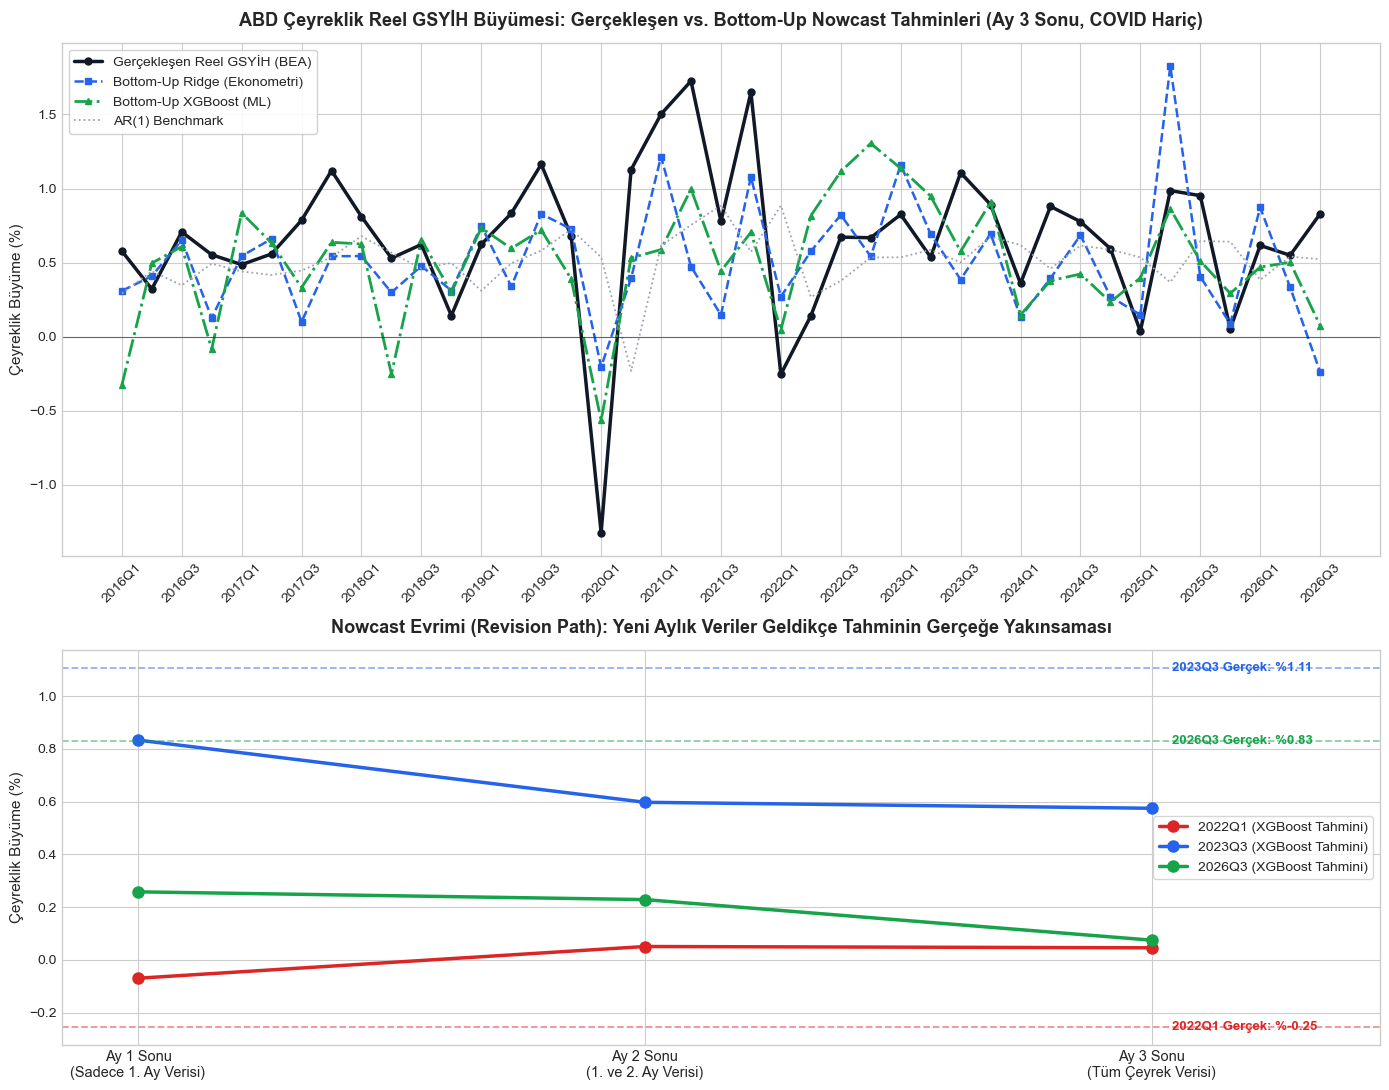

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns


def build_realtime_feature_row(
    target_q: pd.Period, available_months: int
) -> pd.Series:
    q_start_month = (target_q.quarter - 1) * 3 + 1
    m1_p = pd.Period(year=target_q.year, month=q_start_month, freq="M")
    m2_p = m1_p + 1
    m3_p = m1_p + 2

    sim_cutoff_p = [m1_p, m2_p, m3_p][available_months - 1]
    row_dict = {}

    for col in feature_cols:
        s_valid = m_proc[col].dropna()
        avail_hist = s_valid[s_valid.index <= sim_cutoff_p]
        last_real_p = avail_hist.index[-1]

        vals = []
        for p in [m1_p, m2_p, m3_p]:
            if p <= last_real_p and p in avail_hist.index:
                vals.append(avail_hist.loc[p])
            else:
                step_ahead = (p.year - last_real_p.year) * 12 + (
                    p.month - last_real_p.month
                )
                step_ahead = max(1, step_ahead)  # steps'in en az 1 olmasını garantile
                f_vals = forecast_missing_months(avail_hist, last_real_p, step_ahead)
                vals.append(f_vals[-1])

        row_dict[f"{col}_m1"] = vals[0]
        row_dict[f"{col}_m2"] = vals[1]
        row_dict[f"{col}_m3"] = vals[2]

    return pd.Series(row_dict)


# 1. Backtest sonuçlarını hesapla
records = []
for q in test_quarters:
    actual_gdp = float(master_df.loc[q, "g_real_GDP"])
    for m_avail in [1, 2, 3]:
        r_pred, m_pred, b_pred, _ = predict_single_quarter(
            q, available_months=m_avail, mask_covid=True
        )
        records.append({
            "Quarter": q,
            "Quarter_Str": str(q),
            "Month_Avail": m_avail,
            "Actual": actual_gdp,
            "Ridge": r_pred,
            ml_name: m_pred,
            "AR1_Benchmark": b_pred,
        })

bt_df = pd.DataFrame(records)

# 2. Grafikleri çizdir
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(
    2, 1, figsize=(14, 11), gridspec_kw={"height_ratios": [1.3, 1]}
)

# PANEL 1: Backtest Zaman Serisi (2016Q1 - 2026Q3, Ay 3 Sonu)
ax1 = axes[0]
sub_m3 = bt_df[
    (bt_df["Month_Avail"] == 3) & (~bt_df["Quarter"].isin(covid_quarters))
].copy()

ax1.plot(
    sub_m3["Quarter_Str"],
    sub_m3["Actual"],
    label="Gerçekleşen Reel GSYİH (BEA)",
    color="#111827",
    linewidth=2.5,
    marker="o",
    markersize=5,
)
ax1.plot(
    sub_m3["Quarter_Str"],
    sub_m3["Ridge"],
    label="Bottom-Up Ridge (Ekonometri)",
    color="#2563EB",
    linewidth=1.8,
    linestyle="--",
    marker="s",
    markersize=4,
)
ax1.plot(
    sub_m3["Quarter_Str"],
    sub_m3[ml_name],
    label=f"Bottom-Up {ml_name} (ML)",
    color="#16A34A",
    linewidth=2.0,
    linestyle="-.",
    marker="^",
    markersize=5,
)
ax1.plot(
    sub_m3["Quarter_Str"],
    sub_m3["AR1_Benchmark"],
    label="AR(1) Benchmark",
    color="#9CA3AF",
    linewidth=1.3,
    linestyle=":",
)

ax1.axhline(0, color="black", linewidth=0.8, alpha=0.5)
ax1.set_title(
    "ABD Çeyreklik Reel GSYİH Büyümesi: Gerçekleşen vs. Bottom-Up Nowcast Tahminleri (Ay 3 Sonu, COVID Hariç)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax1.set_ylabel("Çeyreklik Büyüme (%)", fontsize=11)
ax1.tick_params(axis="x", rotation=45)
ax1.set_xticks(range(0, len(sub_m3), 2))
ax1.set_xticklabels(sub_m3["Quarter_Str"].iloc[::2])
ax1.legend(
    loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=10
)

# PANEL 2: Nowcast Evrimi (Revision Path - Ay 1 -> Ay 2 -> Ay 3)
ax2 = axes[1]
selected_quarters = ["2022Q1", "2023Q3", "2026Q3"]
colors = ["#DC2626", "#2563EB", "#16A34A"]

x_positions = [1, 2, 3]
x_labels = [
    "Ay 1 Sonu\n(Sadece 1. Ay Verisi)",
    "Ay 2 Sonu\n(1. ve 2. Ay Verisi)",
    "Ay 3 Sonu\n(Tüm Çeyrek Verisi)",
]

for q_str, col in zip(selected_quarters, colors):
    q_sub = bt_df[bt_df["Quarter_Str"] == q_str].sort_values("Month_Avail")
    if len(q_sub) == 3:
        actual_val = q_sub["Actual"].iloc[0]
        ax2.plot(
            x_positions,
            q_sub[ml_name],
            marker="o",
            markersize=8,
            linewidth=2.5,
            color=col,
            label=f"{q_str} ({ml_name} Tahmini)",
        )
        ax2.axhline(actual_val, color=col, linestyle="--", alpha=0.5, linewidth=1.3)
        ax2.text(
            3.04,
            actual_val,
            f"{q_str} Gerçek: %{actual_val:.2f}",
            color=col,
            va="center",
            fontsize=9.5,
            fontweight="bold",
        )

ax2.set_xlim(0.85, 3.45)
ax2.set_xticks(x_positions)
ax2.set_xticklabels(x_labels, fontsize=10.5)
ax2.set_ylabel("Çeyreklik Büyüme (%)", fontsize=11)
ax2.set_title(
    "Nowcast Evrimi (Revision Path): Yeni Aylık Veriler Geldikçe Tahminin Gerçeğe Yakınsaması",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax2.legend(loc="best", frameon=True, facecolor="white", fontsize=10)

plt.tight_layout()
plt.savefig("gdp_nowcast_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()